# Case Study 14 — "Buy Me That Look": Visual Similar-Item Retrieval for Every Garment in a Model Image (Myntra ShopLook)

**Priority:** ★★ Good to have · **Reference:** Case Study 14 — *Myntra ShopLook* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Personalisation, Product (fashion product page), Computer-vision lead, Finance
**Data:** ⚠️ **SYNTHETIC** (D-14-01). No images and no deep networks: image **embeddings are simulated** with a hidden "true visual identity" for each item. This is an interview-standard solution, not a reproduction of Myntra's system.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs14_visual_similarity_recommendations.ipynb`

## 0. Executive Summary for Business

*(Simulated image embeddings with a hidden true visual identity, built on the documented design of Myntra's ShopLook: detect garments, embed each with a triplet network, retrieve by cosine. Myntra's images, labels and A/B control are not public, so no company number is reproduced. Written after the analysis.)*

- **The question:** can we show visually similar catalogue items for every garment in a model image, which embedding should do it, and what is it worth?
- **A trained embedding wins by a wide margin.** The triplet-trained projection has **NDCG@5 of 0.563** (95% CI 0.556 to 0.570) against 0.351 for the frozen backbone with cosine, 0.348 with Euclidean and 0.134 for in-type best-sellers. Strict P@3 is **45.3%** against 22.3% for frozen cosine. All gaps are significant on the same garments except against the colour histogram on "at least one relevant in the top 5" (McNemar Holm p = 0.33), though its NDCG@5 (0.384) is clearly lower.
- **Whitening alone hurts.** PCA-whitening the frozen embedding drops NDCG@5 to 0.269, below the plain frozen embedding. Unsupervised clean-up does not remove nuisance; supervised pairs do.
- **The detector decides how much of the outfit is covered.** Active learning lifts garments with a relevant recommendation in every group (all Holm p < 0.0001): skirts **51.0% to 68.5%**, bags 67.0% to 75.3%, topwear 80.9% to 86.1%. Outfits where every garment gets a relevant item rise from **49.2% to 59.6%**. Badly cut crops hurt: 90.3% relevant versus 99.0% for clean crops.
- **Strict labels understate relevance.** For the trained embedding strict P@3 is 45.3% but lenient relevance is 79.9%, a gap of 35 points (CI 34 to 35). Our simulated expert review judged **77.4%** relevant (CI 73.5% to 80.8%); it does **not** reproduce the documented 477/500 (95.4%), because our relevance rule is our own.
- **Offline and online disagree on the middle.** Spearman between NDCG@5 and twin click-through is only **+0.09**: the colour histogram ranks second offline but near the bottom online, while best-sellers beat the frozen embeddings on clicks (5.6% vs 4.3%). The trained embedding is best on both (CTR 6.3%, add-to-cart 1.43%).
- **A/B sizing:** a 25% click lift needs about 1,700 users per arm, but a **4% add-to-cart lift needs about 4.7 lakh users per arm** under our twin rates. The documented +4% would be hard to confirm.
- **Money (assumed traffic and margin):** about **₹98 crore a year** over best-sellers in the base case (best ₹141 crore, worst ₹27 crore), before an assumed ₹3 crore running cost. Treat it as an order of magnitude: every rupee input is ours.

## 1. The Problem in Simple English

A shopper opens a product page. The photo shows a model wearing a shirt, jeans, a belt and sneakers. The shopper may like the **look**, not just the shirt they searched for. ShopLook tries to answer: *"for every garment in this picture, show me similar products from the catalogue that I can buy."*

Doing this by hand is impossible at catalogue scale, so a pipeline does it: **find the garments** in the image, **cut each out**, turn each cut-out into a list of numbers (an **embedding**) so that visually similar items have nearby numbers, then **look up the nearest catalogue items**.

Leaders and interviewers want to know:
1. How much better is a **trained** embedding than a generic one, and than non-visual rules like best-sellers?
2. Where does the **detector** lose garments, and what did **active learning** buy?
3. Why does **Precision@K look low** while shoppers or experts say the items are relevant?
4. Does the **offline winner** also win **online**, and how big must an A/B test be to see it?
5. What is it worth in ₹, with honest best, base and worst cases?

## 2. Reference from the Case File

### (a) What Myntra documented — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Product pages show a model wearing a full outfit; shoppers may want similar items for every garment worn. The authors state this supports cross-selling and engagement |
| Question | Given a full-shot catalogue image, detect each garment and recommend visually similar catalogue products for each |
| Pipeline | (1) full-shot detection with human keypoints (head and ankle present) plus a pose classifier; (2) article localisation with Mask R-CNN for about 20 apparel types, with an active-learning loop; (3) a triplet-network embedding per detected article (shared-weight ResNet50 branches, margin 0.2, embedding size 2048, semi-hard mining, Street2Shop pairs for hard anchor-positive pairs); (4) cosine-similarity retrieval against the catalogue |
| Detection | Mask R-CNN mean AP 78%. Active learning raised AP: topwear 82.65 to 87.60, bottomwear 87.11 to 90.25, skirts 51.42 to 69.09, footwear 87.32 to 88.47, bags 69.71 to 78.37 |
| Retrieval | P@3 28.4, R@3 15.5, P@5 24.6, R@5 26.1, P@10 15.8, R@10 37.6, beating the baselines (EUC, CE, SIFT) at every K |
| Expert review | 477 of 500 sampled recommendations judged visually relevant (about 95%) |
| Online | Authors report a click-through rise of 25%, add-to-cart ratio up 4% and longer sessions. The reference notes the wording was paraphrased by a fetch tool and **not verified**; **no duration, sample size or significance** is given |
| Latency (V100) | pose about 200 ms, detection about 400 ms, embedding about 100 ms, retrieval about 5 ms per image |

**Source:** Ravi, Repakula, Dutta, Parmar, "Buy Me That Look: An Approach for Recommending Similar Fashion Products", arXiv 2008.11638 (IEEE MIPR 2021). Evidence level: strong (company authors), but the **method detail on data, the control arm, serving and rollout is thin**.

**Honesty note:** the paper is public but the images, labels and the A/B control are not. This notebook solves the same problem on simulated embeddings with a known truth. It is **not** a reproduction of the company's system, and none of its numbers are expected to match theirs.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Catalogue | 6,000 items (plus 60 near-duplicate listings), 10 article types in the 5 documented groups (topwear, bottomwear, skirts, footwear, bags), colour (8), pattern (6) and style (5). Each item has a hidden 14-dimension "true visual identity" |
| Embeddings | A frozen "backbone" of 64 numbers = linear mix of the identity + nuisance factors (background, pose, lighting) + noise. Studio catalogue photos are cleanest, model photos noisier, street photos noisiest and shifted (domain shift) |
| Outfits | 2,500 model images, 2 to 4 garments each (7,201 garments). A garment is detected with probability equal to its group's AP before or after active learning (our assumption), and a badly cut crop leaks part of a neighbouring garment into the query |
| Methods compared | (0) in-type best-sellers (non-visual); (1) colour histogram (handcrafted); (2) frozen backbone, Euclidean; (3) frozen backbone, cosine; (4) PCA-whitened frozen embedding; (5) **triplet-trained** embedding, a linear projection learned with a triplet loss and semi-hard mining (a numpy stand-in for the paper's ResNet50 triplet network) |
| Statistics added | Paired tests and **outfit-cluster bootstrap** CIs; Holm; McNemar for active learning by group; strict-label vs lenient "expert" relevance; simulated expert review with annotator noise and kappa; hubness and coverage; **digital-twin online test**; A/B sample size; retrieval timing |

### (c) How the industry uses this

"Shop the look", "similar products" and visual search are on most fashion marketplaces (Myntra, Flipkart, Ajio, Nykaa Fashion, Amazon Fashion; Pinterest-style visual search globally). The usual design is **per-article-type indexes of embeddings with approximate nearest-neighbour search**, a re-ranker for price, stock and margin, and an online test on click-through and add-to-cart. This case is asked less often than Case 15 but is a standard computer-vision-meets-recommendation question.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we ship ShopLook (visual similar items for each garment), and what must it get right to pay for itself? |
| Analytical | Which embedding gives the most relevant neighbours, where does the pipeline lose garments, and does the offline winner also win online? |

**Hypotheses**
- **H1:** H0: the triplet-trained embedding has the same NDCG@5 as the frozen cosine embedding (and the other methods); paired, outfit-cluster bootstrap, Holm.
- **H2:** H0: active learning does not change the share of garments that end with a relevant recommendation, in each documented group (paired McNemar, Holm).
- **H3:** H0: strict label-match Precision@K and lenient ("expert-style") relevance@K are equal, i.e. offline label metrics do not understate perceived relevance.
- **H4:** H0: the offline ranking of methods equals their ranking in a twin online test (Spearman).
- **H5:** H0: the A/B test can detect a 25% CTR lift and a 4% add-to-cart lift with feasible traffic (sample-size calculation).

**Metrics.** *Strict* = recommended item has the same article type, colour and pattern as the query garment. *Lenient* = same article type, colour within one hue step, and the same pattern or either is plain (our stand-in for an expert's "looks similar"). *Exact-item recall* = the garment's own catalogue item is found (Street2Shop-style round trip). **NDCG@5** uses grades 0/1/2 = not relevant / lenient / strict. **Online proxy** = expected click and add-to-cart rate under the hidden true-similarity model.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Myntra catalogue and model images | **Not public.** The paper describes about 150k training images but releases none |
| Street2Shop (Kiapour et al.) | A public street-to-shop photo set exists, but it is US-centric, needs real images and a deep network, and has no known similarity truth |
| **Decision** | Simulated image embeddings with a hidden true visual identity, so that relevance and an online twin can both be defined (D-14-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs14.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 14 (Myntra ShopLook: visual similar-item retrieval)
=========================================================================================
THIS DATA IS SYNTHETIC. No images and no neural networks are used: image embeddings are SIMULATED.

Documented context (Ravi et al., "Buy Me That Look", arXiv 2008.11638): four-stage pipeline (full-shot detection,
article localisation with Mask R-CNN, triplet-network embedding, cosine retrieval); about 20 apparel types;
Street2Shop pairs for hard positives; active learning lifted detection AP (topwear 82.65 -> 87.60, bottomwear
87.11 -> 90.25, skirts 51.42 -> 69.09, footwear 87.32 -> 88.47, bags 69.71 -> 78.37).

Simulation:
  * Catalogue: 6,000 items, 10 article types in the 5 documented groups, with colour (8 hues), pattern (6) and
    style (5) attributes. Each item has a hidden "true visual identity" vector z (14 dims).
  * "Frozen backbone" embeddings (64 dims) = linear mix of z + nuisance factors (background, pose, lighting)
    + noise. Catalogue photos are clean studio shots, model photos are noisier, street photos noisiest and
    shifted (domain shift). A colour histogram is also observed (the handcrafted baseline).
  * Outfits: 2,500 model images with 2 to 4 garments each. A detector finds each garment with probability equal
    to its group's AP before / after active learning (our assumption: AP used as detection probability); a
    badly localised crop leaks part of another garment's embedding into the query.
  * Training data: 3,600 train items x 2 street photos (Street2Shop-style hard anchors).
Hidden truth for a DIGITAL-TWIN online test: click and add-to-cart probability depend on the true visual
similarity (computed from z) and item popularity.

Outputs: data/cs14/items.csv.gz, garments.csv.gz, embeddings.npz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N_ITEMS, D, ZD, ND = 6000, 64, 14, 16
TYPES = ["tshirt", "shirt", "jacket", "jeans", "trousers", "skirt", "sneakers", "heels", "handbag", "backpack"]
GROUP = ["topwear", "topwear", "topwear", "bottomwear", "bottomwear", "skirts", "footwear", "footwear", "bags", "bags"]
AP_BEFORE = {"topwear": 0.8265, "bottomwear": 0.8711, "skirts": 0.5142, "footwear": 0.8732, "bags": 0.6971}
AP_AFTER = {"topwear": 0.8760, "bottomwear": 0.9025, "skirts": 0.6909, "footwear": 0.8847, "bags": 0.7837}
TYPE_P = np.array([0.17, 0.13, 0.08, 0.13, 0.09, 0.07, 0.10, 0.07, 0.10, 0.06])
COLOURS = ["black", "white", "blue", "red", "green", "yellow", "pink", "brown"]
COLOUR_P = np.array([0.24, 0.16, 0.18, 0.09, 0.08, 0.06, 0.09, 0.10])
PATTERNS = ["solid", "striped", "checked", "floral", "printed", "colourblock"]
PATTERN_P = np.array([0.42, 0.13, 0.11, 0.10, 0.16, 0.08])
N_STYLE = 5
SIG_CAT, SIG_MODEL, SIG_STREET = 0.7, 1.1, 1.6


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---- items and hidden visual identity z -------------------------------------------------
    typ = rng.choice(10, N_ITEMS, p=TYPE_P); col = rng.choice(8, N_ITEMS, p=COLOUR_P); pat = rng.choice(6, N_ITEMS, p=PATTERN_P); sty = rng.integers(0, N_STYLE, N_ITEMS)
    Tc = rng.normal(0, 1.6, (10, 4)); Pc = rng.normal(0, 1.2, (6, 3)); Sc = rng.normal(0, 1.0, (N_STYLE, 3))
    ang = np.arange(8) * 2 * np.pi / 8; Hue = 1.4 * np.stack([np.cos(ang), np.sin(ang)], 1)
    z = np.zeros((N_ITEMS, ZD))
    z[:, 0:4] = Tc[typ] + rng.normal(0, 0.3, (N_ITEMS, 4))
    z[:, 4:6] = Hue[col] + rng.normal(0, 0.18, (N_ITEMS, 2)); z[:, 6:8] = rng.normal(0, 0.5, (N_ITEMS, 2))
    z[:, 8:11] = Pc[pat] + rng.normal(0, 0.25, (N_ITEMS, 3))
    z[:, 11:14] = Sc[sty] + rng.normal(0, 0.5, (N_ITEMS, 3))
    pop = rng.pareto(1.5, N_ITEMS) + 1; logpop = np.log(pop); logpop = (logpop - logpop.mean()) / logpop.std()
    base_price = np.array([649, 899, 1799, 1199, 999, 799, 1499, 1299, 1399, 1099.0])
    price = np.round(base_price[typ] * np.exp(rng.normal(0, 0.45, N_ITEMS)), 0)
    # ---- simulated "frozen backbone" -------------------------------------------------------
    def orth(r, c):
        q, _ = np.linalg.qr(rng.normal(0, 1, (r, c))); return q
    A = 2.2 * orth(D, ZD); B = 2.0 * orth(D, ND)
    d_street = rng.normal(0, 0.8, D); d_model = 0.4 * d_street

    def embed(zz, sigma, offset):
        n = rng.normal(0, 1, (len(zz), ND)) * sigma
        return zz @ A.T + n @ B.T + offset[None, :] + rng.normal(0, 0.35, (len(zz), D))
    E_cat = embed(z, SIG_CAT, np.zeros(D))
    hue_soft = lambda c: np.exp(-0.5 * (np.minimum((np.arange(8)[None, :] - c[:, None]) % 8, (c[:, None] - np.arange(8)[None, :]) % 8) / 0.9) ** 2)
    H_cat = hue_soft(col); H_cat = np.abs(H_cat + rng.normal(0, 0.12, H_cat.shape)); H_cat /= H_cat.sum(1, keepdims=True)
    # ---- train / test split and street training photos -------------------------------------
    perm = rng.permutation(N_ITEMS); train_items = np.sort(perm[:3600]); test_items = np.sort(perm[3600:])
    tr_item = np.repeat(train_items, 2); E_tr = embed(z[tr_item], SIG_STREET, d_street)
    # ---- outfits and garments ----------------------------------------------------------------
    n_out = 2500; ng = rng.choice([2, 3, 4], n_out, p=[0.35, 0.40, 0.25]); rows = []
    by_type = {t: test_items[typ[test_items] == t] for t in range(10)}
    for o in range(n_out):
        ts = rng.choice(10, ng[o], replace=False, p=TYPE_P)
        for t in ts: rows.append((o, int(rng.choice(by_type[int(t)])), int(t)))
    g = pd.DataFrame(rows, columns=["outfit", "item", "article_type"]); Q = len(g)
    g["group"] = [GROUP[t] for t in g.article_type]
    ap_b = g.group.map(AP_BEFORE).values; ap_a = g.group.map(AP_AFTER).values
    u1, u2 = rng.random(Q), rng.random(Q)
    g["detected_before"] = (u1 < ap_b).astype(int); g["detected_after"] = (u1 < ap_a).astype(int)
    g["messy_before"] = (u2 < 1.2 * (1 - ap_b)).astype(int); g["messy_after"] = (u2 < 1.2 * (1 - ap_a)).astype(int)
    g["_leak_u"] = rng.uniform(0.25, 0.55, Q)
    # contaminating garment = another garment in the same outfit (first different row of the outfit)
    first = g.groupby("outfit").cumcount().values; start = g.index.values - first; size = g.groupby("outfit").item.transform("size").values
    other_pos = start + (first + 1) % size
    E_q_clean = embed(z[g.item.values], SIG_MODEL, d_model); E_q_other = E_q_clean[other_pos]
    qhist = hue_soft(col[g.item.values]); H_q = np.abs(qhist + rng.normal(0, 0.28, qhist.shape)); H_q /= H_q.sum(1, keepdims=True)
    # ---- items table incl. data-quality defects --------------------------------------------
    label = typ.copy(); wrong = rng.random(N_ITEMS) < 0.02; label[wrong] = rng.integers(0, 10, wrong.sum())
    items = pd.DataFrame({"item": np.arange(N_ITEMS), "article_type": [TYPES[t] for t in label], "colour": [COLOURS[c] for c in col], "pattern": [PATTERNS[p] for p in pat],
                          "price_inr": price, "units_90d": rng.poisson(12 * pop), "is_train": np.isin(np.arange(N_ITEMS), train_items).astype(int), "_true_type": typ, "_true_colour": col, "_true_pattern": pat, "_style": sty, "_log_pop_z": logpop})
    for k in range(ZD): items[f"_z{k}"] = z[:, k]
    # near-duplicate listings: 60 items re-listed with an almost identical embedding (a different item id)
    dsrc = rng.choice(test_items, 60, replace=False); dup_ids = np.arange(N_ITEMS, N_ITEMS + 60)
    dup_rows = items.loc[dsrc].copy(); dup_rows["item"] = dup_ids; dup_rows["is_train"] = 0; dup_rows["_dup_of"] = dsrc; items["_dup_of"] = -1
    items = pd.concat([items, dup_rows], ignore_index=True)
    E_cat = np.vstack([E_cat, E_cat[dsrc] + rng.normal(0, 0.05, (60, D))]); H_cat = np.vstack([H_cat, H_cat[dsrc]])
    bad = rng.choice(N_ITEMS, 90, replace=False); E_cat[bad[:60]] = 0.0; E_cat[bad[60:]] = np.nan   # failed image processing
    items["embedding_ok"] = 1; items.loc[bad, "embedding_ok"] = 0
    miss = rng.random(len(items)) < 0.015; items["colour"] = items["colour"].where(~miss, None)
    g["article_type_name"] = [TYPES[t] for t in g.article_type]
    arrays = dict(E_cat=E_cat.astype(np.float32), H_cat=H_cat.astype(np.float32), E_tr=E_tr.astype(np.float32), tr_item=tr_item, E_q_clean=E_q_clean.astype(np.float32),
                  E_q_other=E_q_other.astype(np.float32), H_q=H_q.astype(np.float32))
    return items, g, arrays


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs14"), exist_ok=True)
    it, g, ar = generate(); it.to_csv(os.path.join(here, "cs14", "items.csv.gz"), index=False); g.to_csv(os.path.join(here, "cs14", "garments.csv.gz"), index=False)
    np.savez_compressed(os.path.join(here, "cs14", "embeddings.npz"), **ar); print(len(it), "items", len(g), "garments", {k: v.shape for k, v in ar.items()})

Overwriting data/generate_cs14.py


In [3]:
os.makedirs("data/cs14", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs14 as gen; importlib.reload(gen)
t0 = time.time(); items, garm, AR = gen.generate(seed=SEED)
items.to_csv("data/cs14/items.csv.gz", index=False); garm.to_csv("data/cs14/garments.csv.gz", index=False); np.savez_compressed("data/cs14/embeddings.npz", **AR)
print(f"{len(items):,} catalogue items | {len(garm):,} garments in {garm.outfit.nunique():,} outfits | {len(AR['E_tr']):,} street training photos | generated in {time.time() - t0:.0f}s")
garm.head(4)

6,060 catalogue items | 7,201 garments in 2,500 outfits | 7,200 street training photos | generated in 30s


,outfit,item,article_type,group,detected_before,detected_after,messy_before,messy_after,_leak_u,article_type_name
0,0,3491,0,topwear,1,1,0,0,0.4384,tshirt
1,0,471,3,bottomwear,1,1,0,0,0.3182,jeans
2,0,1234,1,topwear,1,1,0,0,0.5305,shirt
3,0,4442,8,bags,1,1,1,1,0.2846,handbag


| Parameter | Value | Basis |
|---|---|---|
| Scale | 6,000 items, 10 types in 5 documented groups, 2,500 outfits | Our assumption (paper: about 150k training images, about 20 types) |
| Embedding | 64 dims = 14-dim identity + 16 nuisance factors + noise; catalogue / model / street nuisance sd 0.7 / 1.1 / 1.6 | Our assumption |
| Detector | P(detect) = documented group AP, before (82.65, 87.11, 51.42, 87.32, 69.71) or after (87.60, 90.25, 69.09, 88.47, 78.37) active learning | **Documented** AP numbers, used as detection probabilities by assumption (AP is not recall) |
| Crop leakage | clean crops leak 4% of a neighbouring garment; badly cut crops (probability 1.2 × (1 − AP)) leak 25–55% | Our assumption |
| Training pairs | 3,600 train items × 2 street photos paired with the catalogue photo | Mirrors Street2Shop pairs |
| Twin | click = exposure(rank) × sigmoid(−6.4 + 3.0 × true similarity + 0.3 × popularity); add-to-cart given click = sigmoid(−2.6 + 1.6 × similarity) | Our assumption (hidden truth) |
| DQ issues | 60 near-duplicate listings, 90 failed embeddings, about 2% wrong article-type labels, 1.5% missing colour | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("items: item, article_type, colour, pattern, price_inr, units_90d", "Catalogue item and its (possibly wrong or missing) labels; observed 90-day sales"),
    ("items: is_train, embedding_ok", "1 if the item is in the metric-learning train split; 0 if its image embedding failed"),
    ("garments: outfit, item, article_type, group", "A garment worn in a model image, the catalogue item it is, its type and documented detector group"),
    ("garments: detected_before / detected_after", "Detector found the garment before / after active learning"),
    ("garments: messy_before / messy_after, _leak_u", "Crop was badly localised; hidden leak share of a neighbouring garment"),
    ("embeddings.npz: E_cat, H_cat", "Catalogue backbone embedding (64) and colour histogram (8)"),
    ("embeddings.npz: E_tr, tr_item", "Street training photos and the item each pairs with"),
    ("embeddings.npz: E_q_clean, E_q_other, H_q", "Model-photo garment embedding, the neighbouring garment's embedding (leakage), query colour histogram"),
    ("items: _true_type/_true_colour/_true_pattern/_style/_log_pop_z/_z0.._z13/_dup_of", "HIDDEN truth (relevance, audit and digital twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs14/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"items: item, article_type, colour, pattern, pr...",Catalogue item and its (possibly wrong or miss...
1,"items: is_train, embedding_ok",1 if the item is in the metric-learning train ...
2,"garments: outfit, item, article_type, group","A garment worn in a model image, the catalogue..."
3,garments: detected_before / detected_after,Detector found the garment before / after acti...
4,"garments: messy_before / messy_after, _leak_u",Crop was badly localised; hidden leak share of...
5,"embeddings.npz: E_cat, H_cat",Catalogue backbone embedding (64) and colour h...
6,"embeddings.npz: E_tr, tr_item",Street training photos and the item each pairs...
7,"embeddings.npz: E_q_clean, E_q_other, H_q","Model-photo garment embedding, the neighbourin..."
8,items: _true_type/_true_colour/_true_pattern/_...,"HIDDEN truth (relevance, audit and digital twi..."


## 5. Data Quality Checks

In [5]:
NT = len(gen.TYPES); Ecat = AR["E_cat"].astype(float); nan_r = np.isnan(Ecat).any(1); zero_r = (~nan_r) & (np.abs(np.nan_to_num(Ecat)).sum(1) == 0); bad_emb = nan_r | zero_r
lab = items.article_type.map({t: i for i, t in enumerate(gen.TYPES)}).values
Cn = normalize(np.nan_to_num(Ecat)); dup = np.zeros(len(items), bool)
for t in range(NT):
    ids = np.where((lab == t) & ~bad_emb)[0]; Sm = Cn[ids] @ Cn[ids].T; np.fill_diagonal(Sm, 0); ii, jj = np.where(np.triu(Sm > 0.99)); dup[ids[jj]] = True
true_dup = items._dup_of.values >= 0
aud = RNG.choice(len(items), 400, replace=False); mis = (lab[aud] != items._true_type.values[aud]); mlo, mhi = proportion_confint(mis.sum(), len(aud), method="wilson")
gal = ~bad_emb & ~dup
checks = {"failed embeddings (NaN or all-zero)": int(bad_emb.sum()), "near-duplicate listings flagged (cosine > 0.99)": int(dup.sum()), "  of which truly re-listed items": int((dup & true_dup).sum()), "true re-listed items missed": int((true_dup & ~dup).sum()),
          "missing colour label": int(items.colour.isna().sum()), "garments with no detection after active learning": int((garm.detected_after == 0).sum())}
print(pd.Series(checks, name="rows").to_string())
print(f"Label audit of {len(aud)} random items: wrong article type = {mis.mean():.1%} (95% CI {mlo:.1%} to {mhi:.1%})")
Ecl = Ecat[~bad_emb]; ntr = np.linalg.norm(AR["E_tr"], axis=1); nq = np.linalg.norm(AR["E_q_clean"], axis=1); nc_ = np.linalg.norm(Ecl, axis=1)
print(f"Embedding norms: catalogue {nc_.mean():.1f} | model photo {nq.mean():.1f} | street photo {ntr.mean():.1f}")
pair_cos = lambda E1, i1: np.einsum("ij,ij->i", normalize(E1), normalize(np.nan_to_num(Ecat[i1]))).mean()
print(f"Mean cosine to the same item's catalogue photo: street {pair_cos(AR['E_tr'], AR['tr_item']):.3f} | model {pair_cos(AR['E_q_clean'], garm.item.values):.3f}  (domain shift: below 1 even for the same item)")
print(f"Gallery after cleaning: {gal.sum():,} items; detection rate before {garm.detected_before.mean():.1%}, after {garm.detected_after.mean():.1%}")

failed embeddings (NaN or all-zero)                   90
near-duplicate listings flagged (cosine > 0.99)       59
  of which truly re-listed items                      59
true re-listed items missed                            1
missing colour label                                 103
garments with no detection after active learning    1035
Label audit of 400 random items: wrong article type = 1.0% (95% CI 0.4% to 2.5%)
Embedding norms: catalogue 11.8 | model photo 13.8 | street photo 17.7
Mean cosine to the same item's catalogue photo: street 0.476 | model 0.590  (domain shift: below 1 even for the same item)
Gallery after cleaning: 5,911 items; detection rate before 80.3%, after 85.6%


**Observation:** 90 embeddings failed (NaN or all zero) and are excluded from the gallery. The duplicate check (cosine above 0.99) flagged 59 near-duplicate listings, all genuine, and missed 1 of 60. A 400-item label audit found **1.0% wrong article types** (CI 0.4% to 2.5%; we planted about 2%, so the audit sample is a little lucky), and 103 items have no colour. The domain shift is visible: the same item's model photo has mean cosine **0.59** to its catalogue photo and its street photo only **0.48**, and norms grow from 11.8 (catalogue) to 13.8 (model) to 17.7 (street). That gap is why a frozen embedding is a weak retriever and why street-to-shop training pairs matter. The detector misses 1,035 garments (14.4%) even after active learning. The gallery has 5,911 items.

## 6. Exploratory Data Analysis

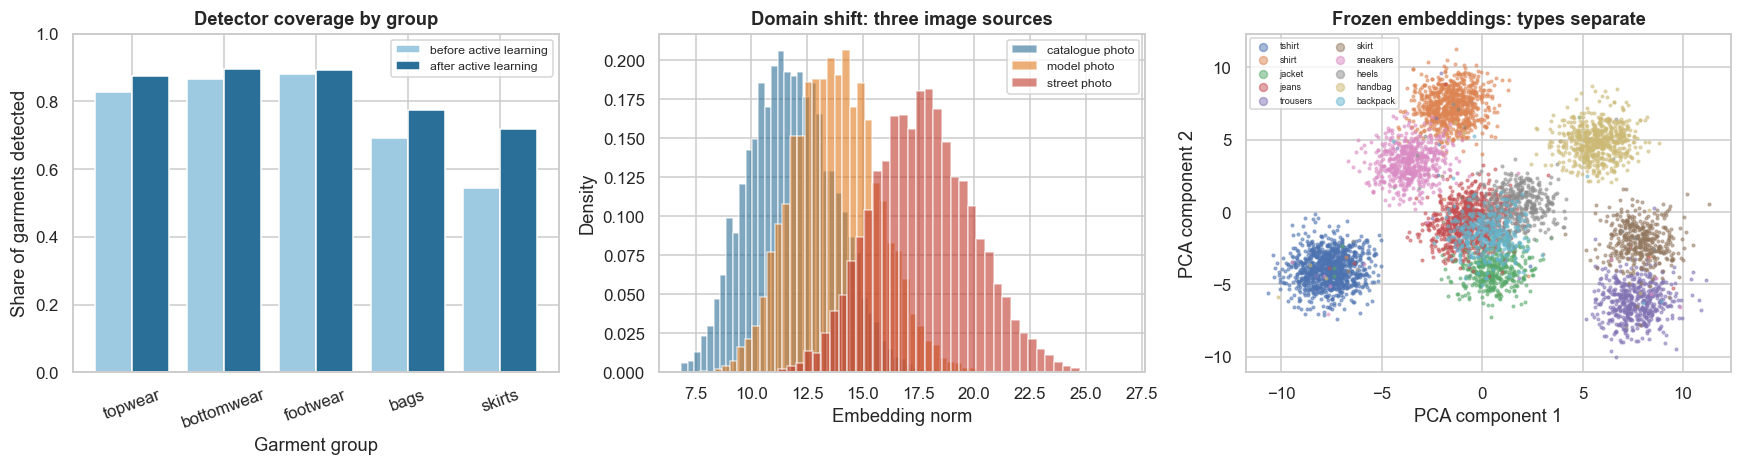

PCA 2 components explain 34.0% of variance | garments per outfit: {2: 901, 3: 997, 4: 602} | colour shares: black 24%, blue 18%, white 16%, brown 10%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
grp = garm.groupby("group").agg(before=("detected_before", "mean"), after=("detected_after", "mean")).loc[["topwear", "bottomwear", "footwear", "bags", "skirts"]]
xx = np.arange(len(grp)); axes[0].bar(xx - 0.2, grp.before, 0.4, color="#9ecae1", label="before active learning"); axes[0].bar(xx + 0.2, grp.after, 0.4, color="#2a6f97", label="after active learning")
axes[0].set_xticks(xx); axes[0].set_xticklabels(grp.index, rotation=20); axes[0].set_ylim(0, 1); axes[0].set_xlabel("Garment group"); axes[0].set_ylabel("Share of garments detected"); axes[0].set_title("Detector coverage by group"); axes[0].legend(fontsize=8)
for nm_, E_, c_ in (("catalogue photo", Ecl, "#2a6f97"), ("model photo", AR["E_q_clean"], "#e07a1f"), ("street photo", AR["E_tr"], "#c0392b")):
    axes[1].hist(np.linalg.norm(E_, axis=1), bins=40, alpha=0.6, color=c_, label=nm_, density=True)
axes[1].set_xlabel("Embedding norm"); axes[1].set_ylabel("Density"); axes[1].set_title("Domain shift: three image sources"); axes[1].legend(fontsize=8)
pc = PCA(2, random_state=SEED).fit(Ecl); P2 = pc.transform(Ecl); tl = lab[~bad_emb]
for t in range(NT): axes[2].scatter(P2[tl == t, 0], P2[tl == t, 1], s=3, alpha=0.5, label=gen.TYPES[t])
axes[2].set_xlabel("PCA component 1"); axes[2].set_ylabel("PCA component 2"); axes[2].set_title("Frozen embeddings: types separate"); axes[2].legend(fontsize=6, markerscale=3, ncol=2)
plt.tight_layout(); plt.show()
print(f"PCA 2 components explain {pc.explained_variance_ratio_.sum():.1%} of variance | garments per outfit: {garm.groupby('outfit').size().value_counts().sort_index().to_dict()} | colour shares: " + ", ".join(f"{c} {s:.0%}" for c, s in items.colour.value_counts(normalize=True).head(4).items()))

**Takeaway:** the detector covers topwear, bottomwear and footwear well but bags and especially skirts poorly, and active learning narrows the gap most for skirts (**54% to 72%** of garments detected in our simulation). The three image sources have clearly different embedding norms, so catalogue, model and street photos are **not interchangeable** for a frozen model. Types separate in the first two principal components, but those two explain only 34.0% of variance, so most of the structure that matters inside a type (colour, pattern, style) is in other directions. Black, blue and white are 58% of items, so colour-based shortcuts will find many plausible matches.

## 7. Statistical Analysis (core section)

### 7.1 Setup: training the embedding and scoring six retrievers

**Protocol.** The detector assigns each garment a type, and retrieval runs **inside that type's index** (as in the paper, per-article-type). Each query is a model-photo crop of a catalogue item; the item itself is **excluded** from the list (the shopper already sees it). Relevance is judged from hidden attributes. We score the garments that the detector found **after active learning**, using their (possibly leaky) crops.

| # | Method | In one line |
|---|---|---|
| 0 | In-type best-sellers | Most-sold items of that type (non-visual control) |
| 1 | Colour histogram | Cosine of 8-bin colour histograms (handcrafted) |
| 2 | Frozen backbone, Euclidean | Nearest by squared distance on raw embeddings |
| 3 | Frozen backbone, cosine | As 2 but cosine |
| 4 | PCA-whitened frozen | Centre, rotate to top 24 principal components, equalise variance, cosine |
| 5 | **Triplet-trained** | Linear 64→24 projection trained on street/catalogue pairs with triplet loss (margin 0.5 in standardised space), semi-hard negatives, Adam, 600 steps of 512; **fixed settings, no tuning** |

#### Code

In [7]:
Ecl_all = np.nan_to_num(Ecat); mu = Ecl_all[gal].mean(0); sd_ = Ecl_all[gal].std(0)
Zc = (Ecl_all - mu) / sd_; Ztr = (AR["E_tr"].astype(float) - mu) / sd_; tri = AR["tr_item"]
def train_triplet(dim=24, iters=600, bs=512, lr=0.01, margin=0.5, seed=SEED):
    r = np.random.default_rng(seed); Z = Ztr; C = Zc; log = []
    W = np.linalg.svd(Z - Z.mean(0), full_matrices=False)[2][:dim].copy() * 0.3; m1 = np.zeros_like(W); v1 = np.zeros_like(W)
    for it in range(1, iters + 1):
        idx = r.integers(0, len(Z), bs); a = Z[idx]; pi = tri[idx]; p = C[pi]; ea = a @ W.T; ep = p @ W.T
        dap = ((ea - ep) ** 2).sum(1); D2 = (ea ** 2).sum(1)[:, None] + (ep ** 2).sum(1)[None, :] - 2 * ea @ ep.T; D2[pi[:, None] == pi[None, :]] = np.inf
        semi = np.where(D2 > dap[:, None], D2, np.inf); j = np.where(np.isfinite(semi).any(1), semi.argmin(1), D2.argmin(1)); n = p[j]
        dan = ((ea - n @ W.T) ** 2).sum(1); loss = np.maximum(0, margin + dap - dan); act = loss > 0
        if it % 20 == 0: log.append((it, loss.mean(), act.mean()))
        if act.sum() == 0: continue
        da = a[act] - p[act]; dn = a[act] - n[act]; G = 2 * (W @ (da.T @ da) - W @ (dn.T @ dn)) / bs
        m1 = 0.9 * m1 + 0.1 * G; v1 = 0.999 * v1 + 0.001 * G * G; W -= lr * (m1 / (1 - 0.9 ** it)) / (np.sqrt(v1 / (1 - 0.999 ** it)) + 1e-8)
    return W, pd.DataFrame(log, columns=["step", "mean triplet loss", "share of active triplets"])
t0 = time.time(); Wt, tlog = train_triplet(); print(f"Triplet training: {time.time() - t0:.1f}s | loss {tlog.iloc[0, 1]:.3f} at step 20 -> {tlog.iloc[-1, 1]:.3f} at step 600 | active triplets {tlog.iloc[0, 2]:.0%} -> {tlog.iloc[-1, 2]:.0%}")
pca_w = PCA(24, whiten=True, random_state=SEED).fit(Zc[gal])
CE = {"2": Zc, "3": Zc, "4": pca_w.transform(Zc), "5": Zc @ Wt.T}; CEn = {k: normalize(v) for k, v in CE.items()}
Hc = AR["H_cat"].astype(float); Hcn = normalize(Hc); Hqn = normalize(AR["H_q"].astype(float))
tt, tc, tp = items._true_type.values, items._true_colour.values, items._true_pattern.values; CAND = [np.where((lab == t) & gal)[0] for t in range(NT)]
Eq_c = AR["E_q_clean"].astype(float); Eq_o = AR["E_q_other"].astype(float)
def mix(messy, leak): lam = np.where(messy == 1, leak, 0.04)[:, None]; return (1 - lam) * Eq_c + lam * Eq_o
EQ_after = mix(garm.messy_after.values, garm._leak_u.values); EQ_before = mix(garm.messy_before.values, garm._leak_u.values)
units = items.units_90d.values.astype(float)
METH = {"0 in-type best-sellers": "0", "1 colour histogram": "1", "2 frozen, Euclidean": "2", "3 frozen, cosine": "3", "4 PCA-whitened frozen": "4", "5 triplet-trained": "5"}
def scorer(m, qs, EQ, cand):
    if m == "0": return np.tile(units[cand] + RNG.random(len(cand)) * 1e-3, (len(qs), 1))
    if m == "1": return Hqn[qs] @ Hcn[cand].T
    if m == "2": q = (EQ[qs] - mu) / sd_; return -((q ** 2).sum(1)[:, None] + (Zc[cand] ** 2).sum(1)[None, :] - 2 * q @ Zc[cand].T)
    if m == "3": return normalize((EQ[qs] - mu) / sd_) @ CEn["3"][cand].T
    if m == "4": return normalize(pca_w.transform((EQ[qs] - mu) / sd_)) @ CEn["4"][cand].T
    return normalize(((EQ[qs] - mu) / sd_) @ Wt.T) @ CEn["5"][cand].T
def evaluate(m, qsel, EQ, K=10):
    n = len(qsel); rec = np.zeros((n, K), int); gr = np.zeros((n, K)); ideal = np.zeros((n, 5)); srank = np.full(n, np.inf); qt = garm.article_type.values[qsel]; qi = garm.item.values[qsel]
    for t in range(NT):
        qm = np.where(qt == t)[0]; cand = CAND[t]
        if len(qm) == 0: continue
        S = scorer(m, qsel[qm], EQ, cand).astype(float); si = np.minimum(np.searchsorted(cand, qi[qm]), len(cand) - 1); inside = cand[si] == qi[qm]; ar_ = np.arange(len(qm))
        ss = S[ar_, si]; rk = 1 + (S > ss[:, None]).sum(1); srank[qm[inside]] = rk[inside]; S[ar_[inside], si[inside]] = -np.inf
        top = np.argsort(-S, axis=1)[:, :K]; rec[qm] = cand[top]
        qa, qb, qc = tt[qi[qm]][:, None], tc[qi[qm]][:, None], tp[qi[qm]][:, None]; cd = np.minimum((tc[cand][None, :] - qb) % 8, (qb - tc[cand][None, :]) % 8)
        strict = (tt[cand][None, :] == qa) & (tc[cand][None, :] == qb) & (tp[cand][None, :] == qc)
        leni = (tt[cand][None, :] == qa) & (cd <= 1) & ((tp[cand][None, :] == qc) | (tp[cand][None, :] == 0) | (qc == 0)); G = strict.astype(int) + leni.astype(int)
        G[ar_[inside], si[inside]] = 0; gr[qm] = np.take_along_axis(G, top, 1); ideal[qm] = -np.sort(-G, axis=1)[:, :5]
    disc = 1 / np.log2(np.arange(2, 7)); dcg = ((2 ** gr[:, :5] - 1) * disc).sum(1); idcg = ((2 ** ideal - 1) * disc).sum(1)
    return dict(rec=rec, gr=gr, ndcg=np.where(idcg > 0, dcg / np.maximum(idcg, 1e-9), np.nan), srank=srank)
qsel = np.where(garm.detected_after.values == 1)[0]; outf = garm.outfit.values[qsel]
t0 = time.time(); EV = {k: evaluate(m, qsel, EQ_after) for k, m in METH.items()}; print(f"Scored {len(qsel):,} detected garments with 6 methods in {time.time() - t0:.0f}s")
def cboot(v, n=1000):
    # outfit-cluster bootstrap mean and 95% CI for a per-query vector (ignores NaN)
    ok = ~np.isnan(v); s = np.bincount(outf[ok], weights=v[ok], minlength=2500); c = np.bincount(outf[ok], minlength=2500).astype(float); w = RNG.multinomial(2500, np.ones(2500) / 2500, size=n)
    est = (w @ s) / (w @ c); return np.nansum(v) / ok.sum(), np.percentile(est, 2.5), np.percentile(est, 97.5)
rows = []
for k, e in EV.items():
    gr = e["gr"]; nd = cboot(e["ndcg"]); s3 = cboot((gr[:, :3] >= 2).mean(1)); l5 = cboot((gr[:, :5] >= 1).mean(1)); sr = e["srank"]
    rows.append((k, nd[0], nd[1], nd[2], s3[0], (gr[:, :5] >= 2).mean(), (gr[:, :10] >= 2).mean(), (gr[:, :3] >= 1).mean(), l5[0], (sr <= 5).mean()))
res = pd.DataFrame(rows, columns=["method", "NDCG@5", "CI low", "CI high", "strict P@3", "strict P@5", "strict P@10", "lenient P@3", "lenient P@5", "exact-item recall@5"]).set_index("method")
res.round(4)

Triplet training: 33.0s | loss 0.011 at step 20 -> 0.002 at step 600 | active triplets 6% -> 1%


Scored 6,166 detected garments with 6 methods in 14s


,NDCG@5,CI low,CI high,strict P@3,strict P@5,strict P@10,lenient P@3,lenient P@5,exact-item recall@5
method,,,,,,,,,
0 in-type best-sellers,0.1337,0.1311,0.1368,0.0365,0.0427,0.0388,0.3166,0.3271,0.0055
1 colour histogram,0.3844,0.3786,0.3901,0.2148,0.2101,0.2089,0.7143,0.7135,0.0584
"2 frozen, Euclidean",0.3477,0.3419,0.3535,0.2201,0.2041,0.1829,0.6124,0.5933,0.2345
"3 frozen, cosine",0.3512,0.3453,0.3565,0.2226,0.2082,0.1870,0.6122,0.5950,0.2522
4 PCA-whitened frozen,0.2688,0.2641,0.2738,0.1445,0.1360,0.1225,0.5179,0.5039,0.1150
5 triplet-trained,0.5633,0.5564,0.5704,0.4525,0.4158,0.3547,0.7986,0.7834,0.8669


**Observation:** the **triplet-trained embedding is best on every visual metric**: NDCG@5 0.563 (CI 0.556 to 0.570), strict P@3 45.3%, lenient P@5 78.3% and exact-item recall@5 **86.7%**, against 25.2% for the frozen cosine embedding. Euclidean (0.348) and cosine (0.351) are equal for practical purposes. **PCA-whitening hurts** (0.269): it equalises variance across directions that are mostly nuisance. The **colour histogram is a surprisingly strong handcrafted baseline** on lenient relevance (P@5 71.4% against 59.5% for frozen cosine) because our lenient rule rewards colour agreement; but its exact-item recall is only 5.8%. In-type best-sellers are almost never strictly relevant (P@3 3.7%) yet lenient P@5 is still 32.7%, simply because the lenient rule is easy to meet inside a type. Training converged: mean triplet loss fell from 0.011 to 0.002 and the share of active triplets from 6% to 1%.

### 7.2 Is the trained embedding really better? Paired tests on the same garments

**(a) Why?** Every method is scored on the **same garments**, so paired tests apply. Garments in the same outfit share a model and a photo style, so they are **not independent**: we estimate the intra-outfit correlation and report outfit-cluster bootstrap CIs. Tests: **McNemar** on "at least one lenient-relevant item in the top 5" (Holm across comparisons), a **paired outfit-cluster bootstrap** for the NDCG@5 difference, and a Wilcoxon signed-rank p-value (not cluster-adjusted, so treat as indicative).

#### Code

In [8]:
best = res["NDCG@5"].idxmax(); rows = []; hit = {k: (e["gr"][:, :5] >= 1).any(1) for k, e in EV.items()}
for k in res.index:
    if k == best: continue
    a, b = hit[best], hit[k]; mc = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True)
    d = EV[best]["ndcg"] - EV[k]["ndcg"]; dm, dlo, dhi = cboot(d); ok = ~np.isnan(d)
    rows.append((k, int((a & ~b).sum()), int((~a & b).sum()), mc.pvalue, dm, dlo, dhi, stats.wilcoxon(EV[best]["ndcg"][ok], EV[k]["ndcg"][ok]).pvalue))
pt = pd.DataFrame(rows, columns=[f"vs {best}", "hits only best", "hits only other", "McNemar p", "ΔNDCG@5 (best − other)", "CI low", "CI high", "Wilcoxon p"]).set_index(f"vs {best}"); pt["p_holm (McNemar)"] = multipletests(pt["McNemar p"], method="holm")[1]
v5 = (EV[best]["gr"][:, :5] >= 1).mean(1); oid = pd.Series(v5).groupby(outf).agg(["mean", "size"]); mbar = oid["size"].mean(); msb = ((oid["mean"] - v5.mean()) ** 2 * oid["size"]).sum() / (len(oid) - 1); msw = ((v5 - oid["mean"].reindex(outf).values) ** 2).sum() / (len(v5) - len(oid))
icc = (msb - msw) / (msb + (mbar - 1) * msw); deff = 1 + (mbar - 1) * max(icc, 0)
sk = stats.skew(EV[best]["ndcg"][~np.isnan(EV[best]["ndcg"])])
print(f"Best method on NDCG@5: {best} | intra-outfit correlation of relevance ρ = {icc:.3f}, mean garments per outfit {mbar:.2f}, design effect {deff:.2f} | skewness of per-garment NDCG@5 = {sk:.2f} (not normal, so Wilcoxon and bootstrap, not t-tests)")
pt.round(4)

Best method on NDCG@5: 5 triplet-trained | intra-outfit correlation of relevance ρ = 0.016, mean garments per outfit 2.49, design effect 1.02 | skewness of per-garment NDCG@5 = -0.27 (not normal, so Wilcoxon and bootstrap, not t-tests)


,hits only best,hits only other,McNemar p,ΔNDCG@5 (best − other),CI low,CI high,Wilcoxon p,p_holm (McNemar)
vs 5 triplet-trained,,,,,,,,
0 in-type best-sellers,1292,109,0.0000,0.4296,0.4232,0.4364,0.0000,0.0000
1 colour histogram,126,143,0.3293,0.1789,0.1717,0.1865,0.0000,0.3293
"2 frozen, Euclidean",304,119,0.0000,0.2156,0.2091,0.2219,0.0000,0.0000
"3 frozen, cosine",303,103,0.0000,0.2122,0.2060,0.2184,0.0000,0.0000
4 PCA-whitened frozen,448,112,0.0000,0.2945,0.2880,0.3007,0.0000,0.0000


**Observation:** the trained embedding beats frozen Euclidean, frozen cosine, PCA-whitened and best-sellers on the same garments: ΔNDCG@5 = +0.216, +0.212, +0.295 and +0.430 with outfit-cluster CIs that exclude zero by a wide margin, and McNemar Holm p < 0.0001 for each. Against the **colour histogram** the NDCG@5 difference is +0.179 (CI 0.172 to 0.187), but the hit-at-least-once McNemar test is **not significant** (Holm p = 0.33; 126 vs 143 discordant garments): the histogram almost always finds some lenient-relevant item, it just ranks them worse. Intra-outfit correlation is only 0.016 (design effect 1.02), so clustering barely matters here; the bootstrap is a safeguard rather than a big correction. Per-garment NDCG@5 has skewness -0.27, so it is close to symmetric, but it is bounded and discrete, so non-parametric tests were still the safer choice. Wilcoxon p-values are very small but are not cluster-adjusted.

### 7.3 The detector: where garments are lost, and what active learning buys

**(a) Why?** The embedding only matters for garments the detector finds and cuts well. We follow every garment through the funnel **before** and **after** active learning (same garments, the later model detects a superset). The end-to-end success is "detected **and** a lenient-relevant item in the top 5", scored with the triplet-trained embedding. Because the two versions are **paired**, we use McNemar per documented group (Holm across the 5 groups). We also compare relevance for **clean vs badly cut crops** and across article types (chi-square).

#### Code

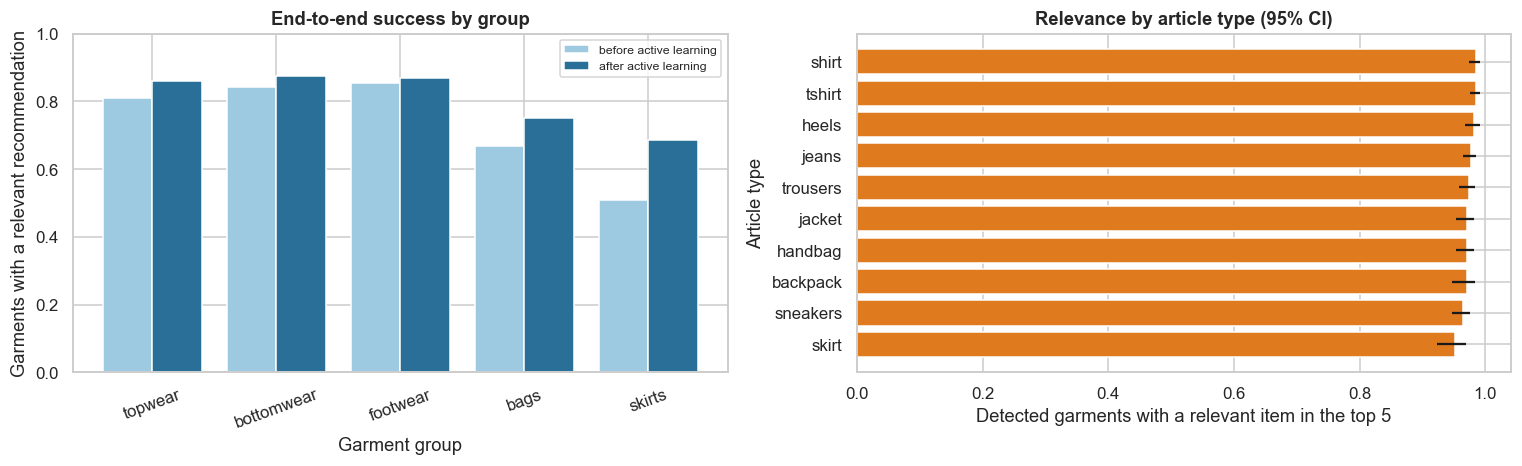

Outfits where EVERY garment gets a relevant recommendation: before 49.2%, after 59.6% | outfits with at least one: before 98.0%, after 98.9%
Relevance given detection: clean crops 99.0% (n = 5119) vs badly cut crops 90.3% (n = 1047); chi-square p = 5e-63 | across 10 article types chi-square p = 0.01, Cramér's V = 0.059


,garments,detected before,detected after,end-to-end before,end-to-end after,gain (pp),gained,lost,McNemar p,p_holm
group,,,,,,,,,,
topwear,2621,0.8279,0.8764,0.8092,0.8607,5.1507,136,1,0.0000,0.0000
bottomwear,1594,0.8657,0.8971,0.8438,0.8758,3.1995,51,0,0.0000,0.0000
footwear,1267,0.8800,0.8942,0.8540,0.8698,1.5785,20,0,0.0000,0.0000
bags,1233,0.6918,0.7753,0.6699,0.7526,8.2725,102,0,0.0000,0.0000
skirts,486,0.5432,0.7202,0.5103,0.6852,17.4897,85,0,0.0000,0.0000


In [9]:
def e2e(det, EQ):
    s = np.where(det == 1)[0]; ev = evaluate("5", s, EQ); out = np.zeros(len(garm), bool); out[s] = (ev["gr"][:, :5] >= 1).any(1); return out, s, ev
ok_b, sb, evb = e2e(garm.detected_before.values, EQ_before); ok_a, sa, eva = e2e(garm.detected_after.values, EQ_after)
rows = []; order = ["topwear", "bottomwear", "footwear", "bags", "skirts"]
for g_ in order:
    m = (garm.group == g_).values; a, b = ok_a[m], ok_b[m]; mc = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=True)
    rows.append((g_, int(m.sum()), garm.detected_before[m].mean(), garm.detected_after[m].mean(), b.mean(), a.mean(), a.mean() - b.mean(), int((a & ~b).sum()), int((~a & b).sum()), mc.pvalue))
fn = pd.DataFrame(rows, columns=["group", "garments", "detected before", "detected after", "end-to-end before", "end-to-end after", "gain (pp)", "gained", "lost", "McNemar p"]).set_index("group"); fn["p_holm"] = multipletests(fn["McNemar p"], method="holm")[1]; fn["gain (pp)"] *= 100
ou = pd.DataFrame({"outfit": garm.outfit.values, "a": ok_a, "b": ok_b}).groupby("outfit").agg(all_a=("a", "all"), all_b=("b", "all"), any_a=("a", "any"), any_b=("b", "any"))
dg = eva["gr"][:, :5]; messy = garm.messy_after.values[sa] == 1; relq = (dg >= 1).any(1); tab = np.array([[relq[~messy].sum(), (~relq[~messy]).sum()], [relq[messy].sum(), (~relq[messy]).sum()]]); chi_m = stats.chi2_contingency(tab, correction=False)
ty = garm.article_type.values[sa]; tab2 = np.array([[relq[ty == t].sum(), (~relq[ty == t]).sum()] for t in range(NT)]); chi_t = stats.chi2_contingency(tab2)
cr = np.sqrt(chi_t[0] / (tab2.sum() * 1))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4)); xx = np.arange(len(order))
axes[0].bar(xx - 0.2, fn.loc[order, "end-to-end before"], 0.4, color="#9ecae1", label="before active learning"); axes[0].bar(xx + 0.2, fn.loc[order, "end-to-end after"], 0.4, color="#2a6f97", label="after active learning")
axes[0].set_xticks(xx); axes[0].set_xticklabels(order, rotation=20); axes[0].set_ylim(0, 1); axes[0].set_xlabel("Garment group"); axes[0].set_ylabel("Garments with a relevant recommendation"); axes[0].set_title("End-to-end success by group"); axes[0].legend(fontsize=8)
rt = pd.Series([relq[ty == t].mean() for t in range(NT)], index=gen.TYPES); ci_ = np.array([proportion_confint(relq[ty == t].sum(), (ty == t).sum(), method="wilson") for t in range(NT)]); o_ = rt.sort_values().index
axes[1].barh(range(NT), rt[o_].values, xerr=[rt[o_].values - ci_[[gen.TYPES.index(i) for i in o_], 0], ci_[[gen.TYPES.index(i) for i in o_], 1] - rt[o_].values], color="#e07a1f"); axes[1].set_yticks(range(NT)); axes[1].set_yticklabels(o_)
axes[1].set_xlabel("Detected garments with a relevant item in the top 5"); axes[1].set_ylabel("Article type"); axes[1].set_title("Relevance by article type (95% CI)")
plt.tight_layout(); plt.show()
print(f"Outfits where EVERY garment gets a relevant recommendation: before {ou.all_b.mean():.1%}, after {ou.all_a.mean():.1%} | outfits with at least one: before {ou.any_b.mean():.1%}, after {ou.any_a.mean():.1%}")
print(f"Relevance given detection: clean crops {relq[~messy].mean():.1%} (n = {int((~messy).sum())}) vs badly cut crops {relq[messy].mean():.1%} (n = {int(messy.sum())}); chi-square p = {chi_m[1]:.2g} | across 10 article types chi-square p = {chi_t[1]:.2g}, Cramér's V = {cr:.3f}")
fn.round(4)

**Takeaway:** active learning raises end-to-end success in all five groups and the gains are paired and significant (Holm p < 0.0001 each; almost every change is a gain, only 1 garment lost, in topwear). The gain is largest where the detector was weakest: **skirts +17.5 points (51.0% to 68.5%)**, bags +8.3, topwear +5.2, bottomwear +3.2, footwear +1.6. Bags and skirts remain the weakest groups. At outfit level the share of images where **every** garment gets a relevant item rises from 49.2% to 59.6%, while at least one garment is covered in 98.0% to 98.9%, so the product is not dead when a detection fails but the full look is. Crop quality matters: relevance is 99.0% for clean crops and 90.3% for badly cut crops (chi-square p = 5e-63). Differences across article types are statistically detectable (p = 0.01) but small (Cramér's V = 0.059), so the main driver is detection and cropping, not which type it is.

### 7.4 Why Precision@K looks low: strict labels vs lenient relevance, and a simulated expert review

**(a) Why?** The paper's label-matching metrics (P@3 = 28.4) look weak next to its expert review (477 of 500, about 95%). Offline labels count a result right only if it matches the **annotated** pair, but a shopper accepts **similar-looking** items. We reproduce the mechanism: strict (same type, colour, pattern) vs lenient relevance by K for the frozen-cosine and trained embeddings, with a paired outfit-cluster CI on the gap at K = 3. Then a **simulated expert review**: 500 random (query, top-3 item) pairs from the trained embedding are judged by two annotators, each of whom flips the lenient truth with probability 5% (our assumption). We report the relevant share with a Wilson CI, Cohen's kappa between annotators, and the documented 477/500 for comparison. Our "expert" rule is our own and need not match Myntra's.

#### Code

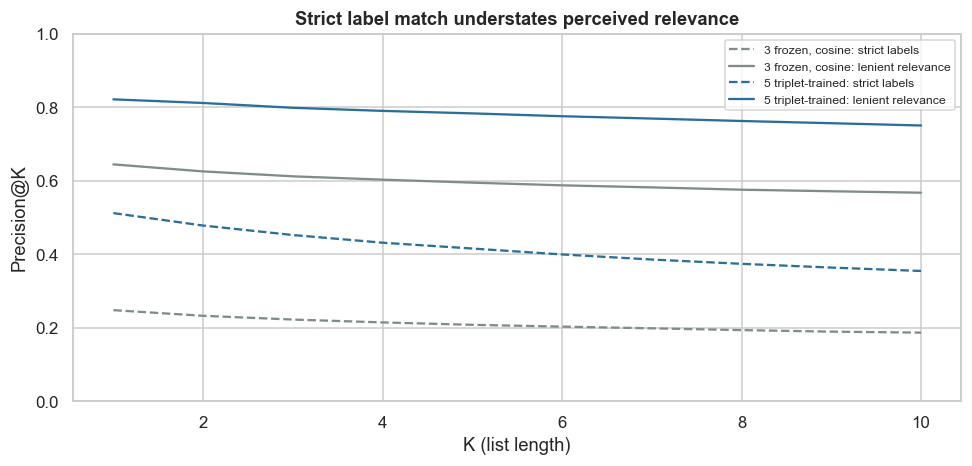

Gap lenient − strict at K = 3 (95% outfit-cluster CI): frozen 0.390 (0.382 to 0.397); trained 0.346 (0.338 to 0.354)
Simulated expert review of 500 trained-embedding recommendations: 387 judged relevant = 77.4% (95% CI 73.5% to 80.8%); true lenient rate in the sample 81.4%; annotator kappa 0.70 | documented: 477/500 = 95.4% (Wilson CI 93.2% to 96.9%)


,1,2,3,4,5,6,7,8,9,10
strict P@K (trained),0.5120,0.4780,0.4530,0.4320,0.4160,0.4000,0.3860,0.3740,0.3640,0.3550
lenient P@K (trained),0.8220,0.8120,0.7990,0.7900,0.7830,0.7760,0.7690,0.7630,0.7570,0.7500
strict P@K (frozen cos),0.2480,0.2330,0.2230,0.2150,0.2080,0.2030,0.1990,0.1940,0.1900,0.1870
lenient P@K (frozen cos),0.6450,0.6260,0.6120,0.6030,0.5950,0.5880,0.5820,0.5760,0.5720,0.5680


In [10]:
Ks = np.arange(1, 11); curves = {}
for k in ("3 frozen, cosine", "5 triplet-trained"):
    g_ = EV[k]["gr"]; curves[k] = ((g_ >= 2).cumsum(1) / Ks).mean(0), ((g_ >= 1).cumsum(1) / Ks).mean(0)
gap = {}
for k in ("3 frozen, cosine", "5 triplet-trained"): gap[k] = cboot((EV[k]["gr"][:, :3] >= 1).mean(1) - (EV[k]["gr"][:, :3] >= 2).mean(1))
g5 = EV["5 triplet-trained"]["gr"][:, :3]; pairs = np.array([(i, r) for i in range(len(g5)) for r in range(3)]); pick = RNG.choice(len(pairs), 500, replace=False); truth = np.array([g5[i, r] >= 1 for i, r in pairs[pick]])
annA = truth ^ (RNG.random(500) < 0.05); annB = truth ^ (RNG.random(500) < 0.05); nrel = int(annA.sum()); elo, ehi = proportion_confint(nrel, 500, method="wilson"); plo, phi = proportion_confint(477, 500, method="wilson")
kap = cohen_kappa_score(annA, annB); true_rate = truth.mean()
fig, ax = plt.subplots(figsize=(9, 4.4))
for k, c_ in (("3 frozen, cosine", "#7f8c8d"), ("5 triplet-trained", "#2a6f97")):
    ax.plot(Ks, curves[k][0], "--", color=c_, label=f"{k}: strict labels"); ax.plot(Ks, curves[k][1], "-", color=c_, label=f"{k}: lenient relevance")
ax.set_xlabel("K (list length)"); ax.set_ylabel("Precision@K"); ax.set_title("Strict label match understates perceived relevance"); ax.set_ylim(0, 1); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"Gap lenient − strict at K = 3 (95% outfit-cluster CI): frozen {gap['3 frozen, cosine'][0]:.3f} ({gap['3 frozen, cosine'][1]:.3f} to {gap['3 frozen, cosine'][2]:.3f}); trained {gap['5 triplet-trained'][0]:.3f} ({gap['5 triplet-trained'][1]:.3f} to {gap['5 triplet-trained'][2]:.3f})")
print(f"Simulated expert review of 500 trained-embedding recommendations: {nrel} judged relevant = {nrel / 500:.1%} (95% CI {elo:.1%} to {ehi:.1%}); true lenient rate in the sample {true_rate:.1%}; annotator kappa {kap:.2f} | documented: 477/500 = 95.4% (Wilson CI {plo:.1%} to {phi:.1%})")
pd.DataFrame({"strict P@K (trained)": curves["5 triplet-trained"][0], "lenient P@K (trained)": curves["5 triplet-trained"][1], "strict P@K (frozen cos)": curves["3 frozen, cosine"][0], "lenient P@K (frozen cos)": curves["3 frozen, cosine"][1]}, index=Ks).T.round(3)

**Takeaway:** strict label match understates what a shopper would accept. For the trained embedding, lenient relevance at K = 3 is 79.9% versus strict 45.3%, a **gap of 34.6 points** (CI 33.8 to 35.4); for frozen cosine the gap is 39.0 points (CI 38.2 to 39.7). Both curves fall slowly with K. This reproduces the mechanism behind the paper's low P@3 (28.4) and high expert acceptance, in direction only. Our simulated expert review gave **387 of 500 (77.4%, CI 73.5% to 80.8%)**, with annotator kappa 0.70, against the documented 477/500 (95.4%, CI 93.2% to 96.9%). The documented figure is **higher than ours and outside our CI**; we do not claim to match it, because our lenient rule and the 5% annotator error are assumptions. H3 is rejected: label metrics understate perceived relevance. Use both a strict and a human-judged metric.

### 7.5 Exact-item recall, exposure and "hub" items

**(a) Why?** Two more checks. **Exact-item recall** (the Street2Shop round trip: is the garment's own catalogue item in the top K when we do *not* exclude it?) is a hard, label-based metric, so it is low for similar-looking catalogues even when recommendations are good. **Exposure**: embedding retrieval can create **hubs**, a few items that appear in many lists. We count how often each gallery item is recommended in the top 5, and report catalogue coverage, an exposure Gini, the share of recommendations going to the 10% most-recommended items, and the skewness of the count distribution.

#### Code

In [11]:
rows = []; gal_n = int(gal.sum())
for k, e in EV.items():
    sr = e["srank"]; cnt = np.bincount(e["rec"][:, :5].ravel(), minlength=len(items))[gal]; srt = np.sort(cnt); gini = 1 - 2 * ((srt.cumsum() - srt / 2) / srt.sum()).sum() / len(cnt); top10 = np.sort(cnt)[::-1][:int(0.1 * len(cnt))].sum() / cnt.sum()
    rows.append((k, (sr <= 1).mean(), (sr <= 5).mean(), (sr <= 10).mean(), (cnt > 0).mean(), gini, top10, stats.skew(cnt)))
hub = pd.DataFrame(rows, columns=["method", "exact recall@1", "exact recall@5", "exact recall@10", "gallery coverage", "exposure Gini", "share to top-10% items", "skewness of counts"]).set_index("method"); print(f"Gallery size {gal_n:,}; {len(qsel):,} queries; top-5 lists")
hub.round(4)

Gallery size 5,911; 6,166 queries; top-5 lists


,exact recall@1,exact recall@5,exact recall@10,gallery coverage,exposure Gini,share to top-10% items,skewness of counts
method,,,,,,,
0 in-type best-sellers,0.0018,0.0055,0.0190,0.0098,0.9930,1.0000,12.2222
1 colour histogram,0.0120,0.0584,0.1139,0.8493,0.5236,0.3279,1.7163
"2 frozen, Euclidean",0.0869,0.2345,0.3425,0.8997,0.4934,0.3305,2.1269
"3 frozen, cosine",0.0892,0.2522,0.3596,0.9413,0.4095,0.2686,1.4342
4 PCA-whitened frozen,0.0341,0.1150,0.1758,0.9509,0.4029,0.2676,1.4781
5 triplet-trained,0.6974,0.8669,0.8999,0.9256,0.4143,0.2614,1.0270


**Observation:** exact-item recall is the starkest metric. The trained embedding finds the garment's own catalogue item at rank 1 in **69.7%** of cases and in the top 5 in 86.7%, against 8.9% and 25.2% for frozen cosine and 0.2% and 0.6% for best-sellers. On exposure, the trained embedding is healthy: it reaches 92.6% of the gallery, exposure Gini 0.41, and 26.1% of recommendations go to the top 10% of items, with the lowest skewness (1.03). Frozen Euclidean is more hub-prone (Gini 0.49, skewness 2.13). Best-sellers cover under 1% of the gallery (Gini 0.99). So the trained embedding does not buy accuracy by recommending a few hub items. Whether it over-recommends near-duplicates of the worn item (a diversity question) is not measured here.

### 7.6 Offline vs online: a digital-twin test

**(a) Why?** Offline relevance is our own rule. An online test measures what people **click and add to cart**. In the simulation we know the true click model, so we compute each method's **expected carousel click-through** and **add-to-cart rate** for the top 5 shown (position decay 1/(1 + 0.35 × rank), and a mild popularity effect), then compare with the offline ranking by Spearman. The **control** is in-type best-sellers (what a product page could show without visual similarity; Myntra's actual control is not documented), and we also report lift over the frozen cosine embedding ("version 1"). Lift CIs use the outfit-cluster bootstrap.

#### Code

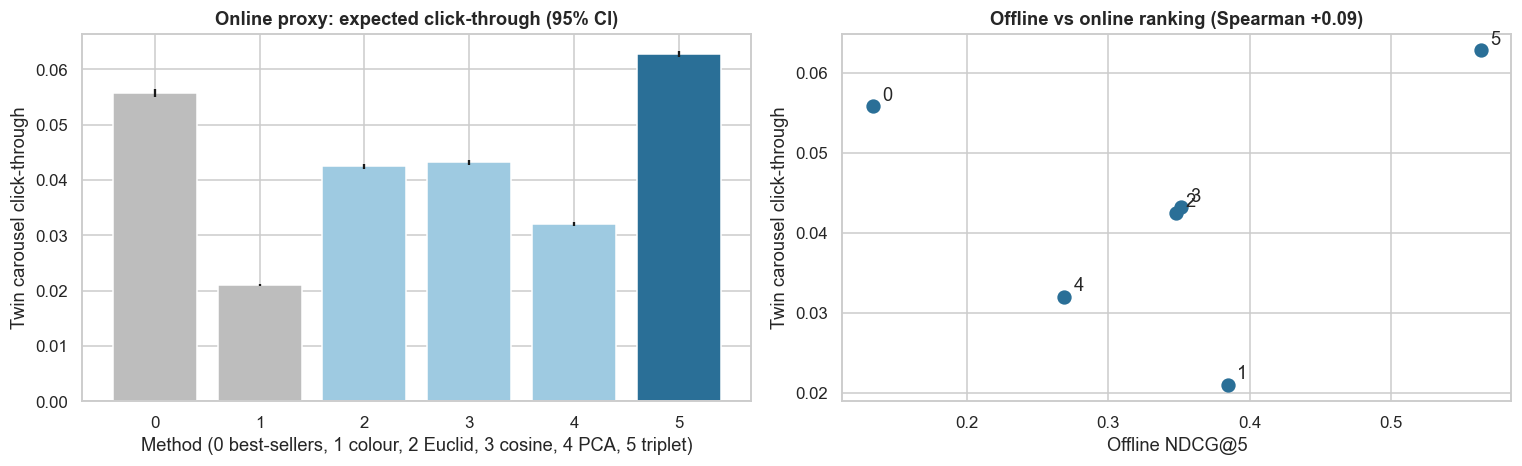

Spearman(offline NDCG@5, twin CTR) = +0.09 (p = 0.87); vs twin ATC = +0.37 | best online: 5 triplet-trained | Wilcoxon p of best-online vs others: 0: 1.2e-107, 1: 0, 2: 0, 3: 0, 4: 0
Trained vs frozen cosine: CTR gain 1.96 pp (CI 1.92 to 2.01); ATC gain 0.56 pp (CI 0.55 to 0.57) | documented claim: CTR +25%, add-to-cart ratio +4% (control unknown, unverified wording)


,twin CTR,CTR CI low,CTR CI high,twin ATC rate,ATC CI low,ATC CI high,CTR lift vs best-sellers,ATC lift vs best-sellers,mean true similarity,NDCG@5 (offline)
method,,,,,,,,,,
0 in-type best-sellers,0.0558,0.0551,0.0565,0.0077,0.0076,0.0079,0.0000,0.0000,0.1230,0.1337
1 colour histogram,0.0210,0.0208,0.0213,0.0034,0.0033,0.0034,-0.6231,-0.5615,0.3234,0.3844
"2 frozen, Euclidean",0.0425,0.0420,0.0429,0.0085,0.0084,0.0086,-0.2389,0.1005,0.6007,0.3477
"3 frozen, cosine",0.0432,0.0427,0.0437,0.0087,0.0086,0.0088,-0.2263,0.1272,0.6090,0.3512
4 PCA-whitened frozen,0.0320,0.0316,0.0324,0.0060,0.0059,0.0060,-0.4261,-0.2304,0.4674,0.2688
5 triplet-trained,0.0628,0.0623,0.0633,0.0143,0.0142,0.0144,0.1251,0.8489,0.7817,0.5633


In [12]:
Zt = items[[f"_z{k}" for k in range(14)]].values[:, 4:]; Znt = normalize(Zt); lpop = items._log_pop_z.values; qi_ = garm.item.values[qsel]
def twin(rec):
    r = rec[:, :5]; s = np.einsum("ij,ikj->ik", Znt[qi_], Znt[r]); ex = 1 / (1 + 0.35 * np.arange(5))[None, :]; pc_ = ex * (1 / (1 + np.exp(-(-6.4 + 3.0 * s + 0.3 * lpop[r]))))
    pa = pc_ * (1 / (1 + np.exp(-(-2.6 + 1.6 * s)))); return 1 - np.prod(1 - pc_, 1), 1 - np.prod(1 - pa, 1), s.mean(1)
TW = {k: twin(e["rec"]) for k, e in EV.items()}; ctl, v1 = "0 in-type best-sellers", "3 frozen, cosine"; rows = []
for k in EV:
    c = cboot(TW[k][0]); a = cboot(TW[k][1]); lc = cboot(TW[k][0] - TW[ctl][0]); la = cboot(TW[k][1] - TW[ctl][1]); rows.append((k, c[0], c[1], c[2], a[0], a[1], a[2], c[0] / TW[ctl][0].mean() - 1, a[0] / TW[ctl][1].mean() - 1, TW[k][2].mean(), res.loc[k, "NDCG@5"]))
on = pd.DataFrame(rows, columns=["method", "twin CTR", "CTR CI low", "CTR CI high", "twin ATC rate", "ATC CI low", "ATC CI high", "CTR lift vs best-sellers", "ATC lift vs best-sellers", "mean true similarity", "NDCG@5 (offline)"]).set_index("method")
rho = stats.spearmanr(on["NDCG@5 (offline)"], on["twin CTR"]); rho_a = stats.spearmanr(on["NDCG@5 (offline)"], on["twin ATC rate"]); best_on = on["twin CTR"].idxmax()
pw = {k: stats.wilcoxon(TW[best_on][0], TW[k][0]).pvalue for k in EV if k != best_on}
l_v1 = cboot(TW["5 triplet-trained"][0] - TW[v1][0]); la_v1 = cboot(TW["5 triplet-trained"][1] - TW[v1][1])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4)); xx = np.arange(len(on)); nm = [k.split(" ", 1)[0] for k in on.index]
axes[0].bar(xx, on["twin CTR"], yerr=[on["twin CTR"] - on["CTR CI low"], on["CTR CI high"] - on["twin CTR"]], color=["#bdbdbd", "#bdbdbd", "#9ecae1", "#9ecae1", "#9ecae1", "#2a6f97"]); axes[0].set_xticks(xx); axes[0].set_xticklabels(nm); axes[0].set_xlabel("Method (0 best-sellers, 1 colour, 2 Euclid, 3 cosine, 4 PCA, 5 triplet)"); axes[0].set_ylabel("Twin carousel click-through"); axes[0].set_title("Online proxy: expected click-through (95% CI)")
axes[1].scatter(on["NDCG@5 (offline)"], on["twin CTR"], s=70, color="#2a6f97")
for n_, x_, y_ in zip(nm, on["NDCG@5 (offline)"], on["twin CTR"]): axes[1].annotate(n_, (x_, y_), textcoords="offset points", xytext=(6, 4))
axes[1].set_xlabel("Offline NDCG@5"); axes[1].set_ylabel("Twin carousel click-through"); axes[1].set_title(f"Offline vs online ranking (Spearman {rho[0]:+.2f})")
plt.tight_layout(); plt.show()
print(f"Spearman(offline NDCG@5, twin CTR) = {rho[0]:+.2f} (p = {rho[1]:.2g}); vs twin ATC = {rho_a[0]:+.2f} | best online: {best_on} | Wilcoxon p of best-online vs others: " + ", ".join(f"{k.split(' ')[0]}: {p:.2g}" for k, p in pw.items()))
print(f"Trained vs frozen cosine: CTR gain {l_v1[0] * 100:.2f} pp (CI {l_v1[1] * 100:.2f} to {l_v1[2] * 100:.2f}); ATC gain {la_v1[0] * 100:.2f} pp (CI {la_v1[1] * 100:.2f} to {la_v1[2] * 100:.2f}) | documented claim: CTR +25%, add-to-cart ratio +4% (control unknown, unverified wording)")
on.round(4)

**Takeaway:** in the twin, the trained embedding is best on both metrics: carousel click-through **6.28%** (CI 6.23% to 6.33%) and add-to-cart rate **1.43%**, versus 5.58% and 0.77% for best-sellers, 4.32% and 0.87% for frozen cosine. That is **+12.5% CTR and +85% add-to-cart over best-sellers**, and about +45% CTR and +64% add-to-cart over frozen cosine. The ordering of the middle methods is not the same as offline: Spearman between offline NDCG@5 and twin CTR is **+0.09 (p = 0.87)**, +0.37 for add-to-cart. The colour histogram looks good offline (NDCG@5 0.384, second) but is nearly worst online (2.1%), and frozen embeddings lose to best-sellers on clicks (popularity pulls clicks in our twin) while winning on add-to-cart. H4 is rejected: offline rank alone is a poor guide except for picking the overall winner. The documented +25% click and +4% add-to-cart have no known control, so our twin lifts neither confirm nor refute them; the twin's click model is assumed.

### 7.7 What would an A/B test need?

**(a) Why?** The paper gives no duration, sample size or significance. We compute **carousels per arm** to detect relative lifts in click-through and add-to-cart (80% power, α = 0.05, two-sided; proportion effect size with the normal approximation), taking the twin's **best-sellers** rates as control. A design effect for repeated carousels per user (3 per session, intra-user correlation 0.05, both assumptions) converts carousels to users. We also show the smallest lift detectable with 5 lakh carousels per arm.

#### Code

In [13]:
pw_ = NormalIndPower(); p0c, p0a = TW[ctl][0].mean(), TW[ctl][1].mean(); deff2 = 1 + 2 * 0.05; rows = []
for lab_, p0, rel in (("CTR +25% (documented claim)", p0c, 0.25), ("CTR +10%", p0c, 0.10), ("add-to-cart +10%", p0a, 0.10), ("add-to-cart +4% (documented claim)", p0a, 0.04)):
    p1 = min(p0 * (1 + rel), 0.999); n_ = pw_.solve_power(effect_size=proportion_effectsize(p1, p0), alpha=0.05, power=0.8); rows.append((lab_, p0, p1, int(np.ceil(n_)), int(np.ceil(n_ * deff2 / 3))))
ss = pd.DataFrame(rows, columns=["target", "control rate", "treatment rate", "carousels per arm (independent)", "users per arm (3 carousels, ICC 0.05)"]).set_index("target")
mde = []
for nm_, p0 in (("CTR", p0c), ("add-to-cart", p0a)):
    es = pw_.solve_power(nobs1=500_000 / deff2, alpha=0.05, power=0.8); lo_, hi_ = p0, min(0.999, p0 * 3)
    for _ in range(40): mid = (lo_ + hi_) / 2; lo_, hi_ = (mid, hi_) if proportion_effectsize(mid, p0) < es else (lo_, mid)
    mde.append((nm_, p0, hi_ / p0 - 1))
print("Smallest detectable relative lift with 5 lakh carousels per arm (design-effect adjusted): " + ", ".join(f"{n}: {m:.1%}" for n, _, m in mde))
ss.round(4)

Smallest detectable relative lift with 5 lakh carousels per arm (design-effect adjusted): CTR: 2.4%, add-to-cart: 6.8%


,control rate,treatment rate,carousels per arm (independent),"users per arm (3 carousels, ICC 0.05)"
target,,,,
CTR +25% (documented claim),0.0558,0.0698,4732,1735
CTR +10%,0.0558,0.0614,27789,10190
add-to-cart +10%,0.0077,0.0085,211327,77487
add-to-cart +4% (documented claim),0.0077,0.0080,1283958,470785


**Observation:** a **25% relative click lift is easy to detect** (about 4,700 carousels, 1,735 users per arm). A 10% click lift needs 27,800 carousels (about 10,200 users). Add-to-cart is the hard metric because it is rare: +10% needs about 77,000 users per arm and the documented **+4% needs about 4.7 lakh users per arm** (12.8 lakh carousels). With 5 lakh carousels per arm the smallest detectable lift is 2.4% for clicks and 6.8% for add-to-cart. So a short test can show the click effect but not a 4% cart effect. H5: the 25% click lift is testable with feasible traffic, the 4% add-to-cart lift only with a long test or a pooled design. These rely on twin control rates (5.6% and 0.77%) that are assumed.

### 7.8 Does retrieval scale? Brute-force timing vs gallery size

**(a) Why?** The paper reports about 5 ms retrieval per image. We time exact (brute-force) nearest-neighbour search on random embeddings for growing gallery sizes, for the 24-dimension trained space and the 64-dimension frozen space, and fit the log-log slope of time per query vs gallery size. This is a sanity check on why production systems add approximate nearest-neighbour indexes; it says nothing about the paper's hardware.

#### Code

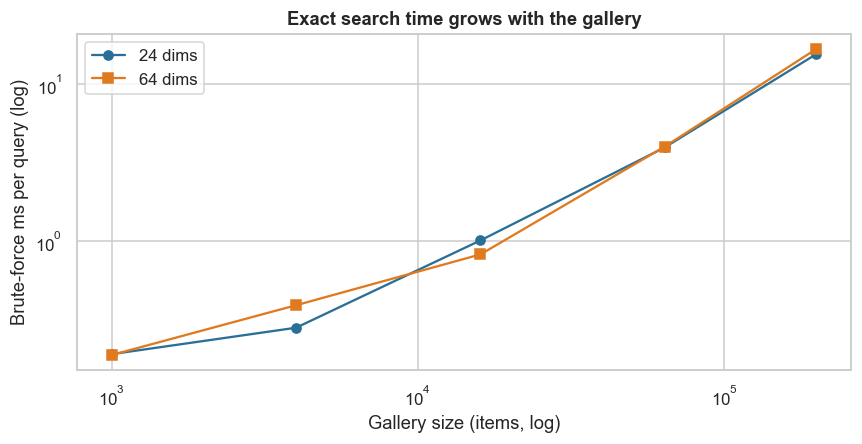

Log-log slope of time vs gallery size: 24 dims 0.85 (R² 0.963); 64 dims 0.84 (R² 0.959) | at 2 lakh items: 15.49 ms (24 dims), 16.70 ms (64 dims) per query


,ms per query (24 dims),ms per query (64 dims)
gallery size,,
1000,0.1890,0.1860
4000,0.2780,0.3870
16000,1.0030,0.8170
64000,3.9350,3.9830
200000,15.4910,16.7030


In [14]:
def time_search(n, d, nq=64, reps=3):
    G = normalize(RNG.normal(size=(n, d)).astype(np.float32)); Q = normalize(RNG.normal(size=(nq, d)).astype(np.float32)); ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); S = Q @ G.T; np.argpartition(-S, 10, axis=1)[:, :10]; ts.append(time.perf_counter() - t0)
    return min(ts) / nq * 1000
_ = time_search(2000, 24, reps=1); sizes = [1000, 4000, 16000, 64000, 200000]; tm = pd.DataFrame({"gallery size": sizes, "ms per query (24 dims)": [time_search(n, 24) for n in sizes], "ms per query (64 dims)": [time_search(n, 64) for n in sizes]}).set_index("gallery size")
sl24 = stats.linregress(np.log(sizes), np.log(tm.iloc[:, 0])); sl64 = stats.linregress(np.log(sizes), np.log(tm.iloc[:, 1]))
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.plot(sizes, tm.iloc[:, 0], "o-", color="#2a6f97", label="24 dims"); ax.plot(sizes, tm.iloc[:, 1], "s-", color="#e07a1f", label="64 dims"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Gallery size (items, log)"); ax.set_ylabel("Brute-force ms per query (log)"); ax.set_title("Exact search time grows with the gallery"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Log-log slope of time vs gallery size: 24 dims {sl24.slope:.2f} (R² {sl24.rvalue ** 2:.3f}); 64 dims {sl64.slope:.2f} (R² {sl64.rvalue ** 2:.3f}) | at 2 lakh items: {tm.iloc[-1, 0]:.2f} ms (24 dims), {tm.iloc[-1, 1]:.2f} ms (64 dims) per query")
tm.round(3)

**Takeaway:** brute-force search time grows almost linearly with gallery size (log-log slope 0.85 for 24 dims, 0.84 for 64 dims; R² about 0.96), reaching about 15 to 17 ms per query at 2 lakh items on this machine. That is above the documented 5 ms retrieval, which used a serving stack the paper does not describe. The 24-dimension and 64-dimension spaces cost about the same here, so the compact embedding mainly helps memory. With catalogues of crores of items and per-type indexes, approximate nearest-neighbour search is needed; our timing does not show its recall trade-off.

## 8. ML Section — what we built and what is beyond it

- **What we built:** a **linear** triplet-trained projection on frozen simulated embeddings. It is a transparent stand-in for the paper's end-to-end ResNet50 triplet network, which learns the features as well as the metric. Stage 1 (full-shot and pose) and Stage 2 (Mask R-CNN) are **not simulated beyond their documented AP**.
- **Beyond this notebook:** hard-pair mining from Street2Shop-like pairs, weighted triplet loss, per-type fine-tuning, approximate nearest-neighbour indexes (HNSW, IVF-PQ), a re-ranker for price, stock and margin (see Case 17) and complementary-item logic ("complete the look"), which the reference file stresses is a different problem.
- **No tuning** (per the brief): margin, learning rate, 24 dimensions and 600 steps were fixed before any result. Below we only show the training curve and a **dimension sensitivity** (8, 16, 24, 48), not a search for the best setting.

#### Code

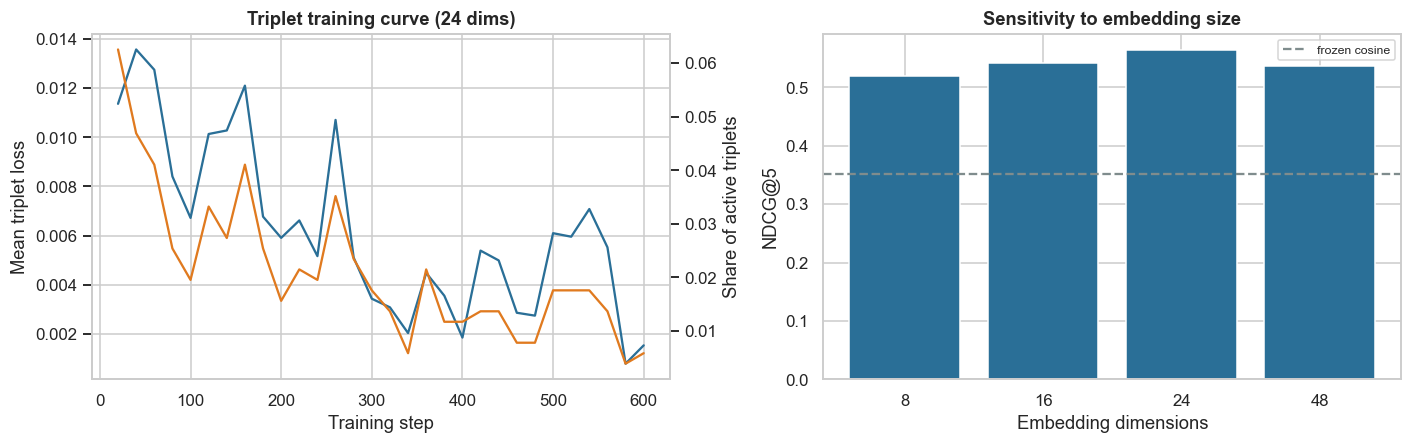

,NDCG@5,strict P@3
embedding dims,,
8,0.5190,0.4218
16,0.5409,0.4380
24,0.5633,0.4525
48,0.5368,0.4263


In [15]:
abl = {24: (Wt, tlog)}
for d_ in (8, 16, 48): abl[d_] = train_triplet(dim=d_)
def ndcg_dim(W_):
    global CE, CEn, Wt
    old = Wt; Wt = W_; CEn["5"] = normalize(Zc @ Wt.T); e = evaluate("5", qsel, EQ_after); Wt = old; CEn["5"] = normalize(Zc @ Wt.T); return np.nanmean(e["ndcg"]), (e["gr"][:, :3] >= 2).mean()
dres = pd.DataFrame({d_: ndcg_dim(abl[d_][0]) for d_ in (8, 16, 24, 48)}, index=["NDCG@5", "strict P@3"]).T; dres.index.name = "embedding dims"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2)); axes[0].plot(tlog["step"], tlog["mean triplet loss"], color="#2a6f97", label="mean triplet loss"); a2 = axes[0].twinx(); a2.plot(tlog["step"], tlog["share of active triplets"], color="#e07a1f", label="share of active triplets"); a2.set_ylabel("Share of active triplets"); a2.grid(False)
axes[0].set_xlabel("Training step"); axes[0].set_ylabel("Mean triplet loss"); axes[0].set_title("Triplet training curve (24 dims)")
axes[1].bar(dres.index.astype(str), dres["NDCG@5"], color="#2a6f97"); axes[1].axhline(res.loc["3 frozen, cosine", "NDCG@5"], color="#7f8c8d", ls="--", label="frozen cosine"); axes[1].set_xlabel("Embedding dimensions"); axes[1].set_ylabel("NDCG@5"); axes[1].set_title("Sensitivity to embedding size"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show(); dres.round(4)

**Takeaway:** the training curve shows loss near zero early (only 6% of triplets active at step 20 and 1% at the end), so most learning happens in the first few hundred steps and the semi-hard mining finds few violating triplets. The dimension check is not a tuning search: NDCG@5 is 0.519 at 8 dims, 0.541 at 16, **0.563 at 24 (our fixed choice)** and 0.537 at 48, all far above the frozen cosine baseline (0.351). The best value being our pre-set choice is luck, not selection. Embedding size matters less than having supervised street-to-shop pairs.

## 9. Business Translation — ₹ impact

Assumptions (D-14-07). Myntra's traffic, order values and the A/B control are not documented, so **all of these are ours**: 60 lakh eligible model-image page views a day; one carousel per detected garment (garments per image and detection rate from the data); a click-and-cart baseline from the twin; 30% of add-to-carts become orders; average order ₹1,150 at a 16% contribution margin; running cost ₹3 crore a year (GPU serving, index refresh, tagging for active learning, a small team). The **comparison is against in-type best-sellers**. Scenarios: **base** = twin lift and 50% incrementality (half of the extra carts would have happened anyway); **best** = upper CI, 70% incrementality; **worst** = lower CI, **half the twin lift** (twin optimism haircut), 30% incrementality, detector at its pre-active-learning level.

#### Code

In [16]:
VIEWS, CART2ORD, AOV, MG, COST = 6e6, 0.30, 1150, 0.16, 3.0
g_per = garm.groupby("outfit").size().mean(); da, db = garm.detected_after.mean(), garm.detected_before.mean()
la = cboot(TW["5 triplet-trained"][1] - TW[ctl][1]); lc = cboot(TW["5 triplet-trained"][0] - TW[ctl][0])
def rupees(dlift, det, incr): return dlift * VIEWS * g_per * det * 365 * CART2ORD * AOV * MG * incr / 1e7
sc = pd.DataFrame({"base": dict(lift=la[0], det=da, incr=0.5), "best": dict(lift=la[2], det=da, incr=0.7), "worst": dict(lift=max(la[1], 0) * 0.5, det=db, incr=0.3)}).T
sc["Δ add-to-cart per carousel (pp)"] = sc.lift * 100; sc["carousels per day (lakh)"] = VIEWS * g_per * sc.det / 1e5; sc["gross ₹ crore / year"] = [rupees(r.lift, r.det, r.incr) for r in sc.itertuples()]; sc["net of ₹3 crore cost"] = sc["gross ₹ crore / year"] - COST
al = rupees(la[0], da, 0.5) - rupees(la[0] * (ok_b.mean() / ok_a.mean()), db, 0.5)
print(f"Garments per image {g_per:.2f}; detection {db:.1%} -> {da:.1%}; end-to-end relevance {ok_b.mean():.1%} -> {ok_a.mean():.1%}; base-case value of active learning ≈ ₹{al:.1f} crore a year (relevance-proportional approximation)")
sc[["Δ add-to-cart per carousel (pp)", "carousels per day (lakh)", "gross ₹ crore / year", "net of ₹3 crore cost"]].round(3)

Garments per image 2.88; detection 80.3% -> 85.6%; end-to-end relevance 78.1% -> 83.5%; base-case value of active learning ≈ ₹12.1 crore a year (relevance-proportional approximation)


,Δ add-to-cart per carousel (pp),carousels per day (lakh),gross ₹ crore / year,net of ₹3 crore cost
base,0.6560,147.9840,97.8440,94.8440
best,0.6740,147.9840,140.6430,137.6430
worst,0.3200,138.7680,26.8130,23.8130


**Takeaway (business reading):** at the assumed traffic (60 lakh model-image views a day, about 148 lakh carousels a day) the base case is about **₹98 crore a year** gross over in-type best-sellers (₹95 crore net of ₹3 crore cost), the best case ₹141 crore and the **worst case ₹27 crore** (₹24 crore net) after halving the twin lift, cutting incrementality to 30% and using the pre-active-learning detector. Active learning alone is worth about ₹12 crore a year in the base case (detection 80.3% to 85.6%, end-to-end relevance 78.1% to 83.5%). The case stays positive in all three scenarios, but every input except the detector APs is assumed and the twin's lift is probably generous, so use the ranking and sign of the result, not the rupee figure.

## 10. Recommendation and Decision

**Recommendation**

1. **Ship ShopLook with a supervised (triplet-trained) embedding, not a frozen one.** NDCG@5 0.56 vs 0.35, exact-item recall@5 87% vs 25%. Do not use unsupervised whitening.
2. **Keep investing in the detector.** Fund the active-learning loop for **skirts and bags**, where gains were 17.5 and 8.3 points, and add a crop-quality check: badly cut crops cost about 9 points of relevance.
3. **Report two relevance metrics**: strict label-match P@K for regression tests and a human-judged relevance share for go/no-go. Strict P@3 understated relevance by about 35 points.
4. **Do not pick the winner on offline rank alone** (Spearman +0.09 with the twin's click-through). Offline screens; A/B decides.
5. **Run an A/B test** on click-through with at least about 1,700 users per arm for a 25% lift and treat add-to-cart as a longer, pooled readout: +4% needs about 4.7 lakh users per arm.
6. **Decision rule:** go live if the triplet embedding shows a significant click lift over the current control with no drop in add-to-cart or session length, and **stop and revisit** if the lift is below 5% at the planned sample or returns rise. Track KPIs: click-through and add-to-cart per carousel, share of outfits fully covered, detection rate by group, badly-cut-crop share, exact-item recall on a weekly audit set, catalogue coverage, latency (p95), returns on ShopLook-driven orders.

## 11. Risks, Limitations and Next Steps

- **Simulated embeddings:** the trained-vs-frozen gap depends entirely on how much nuisance (background, pose, lighting) we put into the frozen embedding and how linear it is. A real ResNet50 is more structured and the gap could be smaller or larger. Re-measure on real images.
- **Our relevance rule is ours:** strict and lenient labels, the 5% annotator error and the twin's click model are assumptions. The simulated expert review is **not** a replication of the documented 95%.
- **AP used as detection probability:** AP is not recall, and per-type APs for our 10 types are group values. The funnel is directional.
- **Linear metric learning only:** no end-to-end features, no hard-pair mining, no pose or full-shot stage. Complementary items ("complete the look") are out of scope.
- **Online claims are unverified:** the documented +25% click-through and +4% add-to-cart come with no control arm, duration or significance. Our twin lifts are not evidence for them.
- **Next steps:** run on a labelled sample of real model images; add a price, stock and margin re-ranker; add approximate nearest-neighbour search; run a live A/B with the sample sizes in 7.7 and a guardrail on session length and returns.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Cosine similarity | a·b / (‖a‖ ‖b‖) |
| Triplet loss | max(0, margin + ‖f(a) − f(p)‖² − ‖f(a) − f(n)‖²) |
| Semi-hard negative | the closest negative that is still farther than the positive |
| Precision@K | share of the top K that are relevant |
| NDCG@5 | Σ (2^grade − 1) / log₂(rank + 1), divided by the best possible ordering |
| Exact-item recall@K | share of queries whose own catalogue item is in the top K |
| Design effect | 1 + (m − 1) ρ, with m items per cluster and intra-cluster correlation ρ |
| Wilson interval | confidence interval for a proportion that behaves at small n and near 0 or 1 |
| McNemar | test on discordant pairs where exactly one of two methods succeeds |

| Term | Meaning |
|---|---|
| Embedding | A list of numbers describing an image so that similar images have nearby lists |
| Triplet network | Trained so an anchor is closer to its positive than to a negative |
| Mask R-CNN | A detector that outlines each object in an image |
| Active learning | Humans correct the model's weakest cases, which are then used to retrain |
| Street2Shop | A public set of street photos paired with shop photos of the same product |
| Domain shift | Studio, model and street photos differ, so embeddings of the same item differ |
| Hubness | A few items appear in many nearest-neighbour lists |
| Digital twin | A simulation where the true behaviour is known |